In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hdfstream
import swiftsimio
import healpy as hp
import lightcone_io as lc
from astropy.cosmology import Planck18
import pandas as pd

In [4]:
root_dir = hdfstream.open("cosma", "/")
h5file = root_dir["FLAMINGO/L1_m8/L1_m8/halo_lightcone/lightcone0/lightcone_halos_0077.hdf5"]
h5file2= root_dir['FLAMINGO/L1_m8/L1_m8/healpix_maps/nside_4096/lightcone0_shells/shell_0/swift_lightcone0.shell_0.0.hdf5']

In [41]:
list(h5file2.keys())

['BlackHoleMass',
 'ComptonY',
 'DM',
 'DarkMatterMass',
 'DopplerB',
 'InternalCodeUnits',
 'NeutrinoMass',
 'Shell',
 'SmoothedGasMass',
 'StarFormationRate',
 'StellarMass',
 'TotalMass',
 'Units',
 'UnsmoothedGasMass',
 'XrayErositaHighIntrinsicEnergies',
 'XrayErositaHighIntrinsicPhotons',
 'XrayErositaLowIntrinsicEnergies',
 'XrayErositaLowIntrinsicPhotons',
 'XrayROSATIntrinsicEnergies',
 'XrayROSATIntrinsicPhotons']

In [9]:
posicion= np.array([750,750,750])

In [42]:
mapa_dm=h5file2['DM'][...]

In [21]:
posición_halo=h5file['Lightcone']['HaloCentre'][:]

In [50]:
halo_z = h5file['Lightcone']['Redshift'][:]

In [54]:
mask = (halo_z >= halo_z.min()) & (halo_z <= halo_z.max())

halo_z_sel = halo_z[mask]
halo_pos_sel = posición_halo[mask]

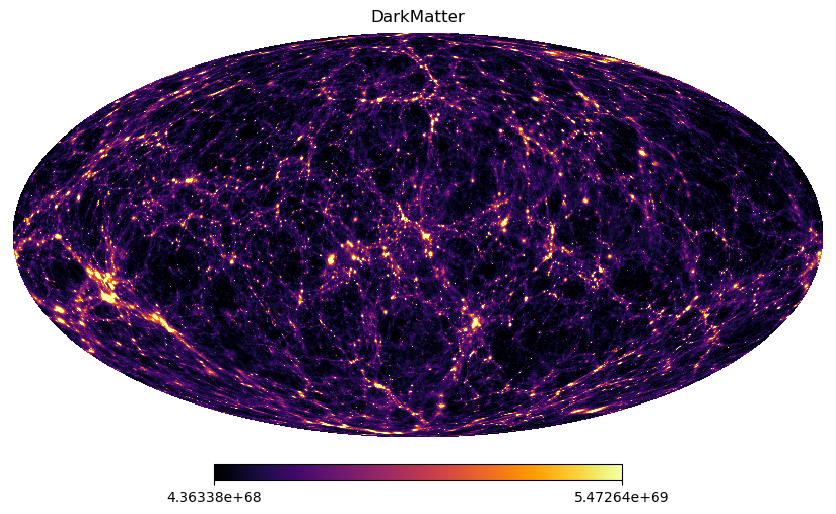

In [43]:
vmin=np.percentile(mapa_dm,1)
vmax=np.percentile(mapa_dm,99)

hp.mollview(mapa_dm,title="DarkMatter",cmap="inferno",min=vmin,max=vmax,unit="")
plt.show()

In [55]:
coord=halo_pos_sel-posicion

In [56]:
x_halo=coord[:,0]
y_halo=coord[:,1]
z_halo=coord[:,2]

In [57]:
r = np.sqrt(x_halo**2 + y_halo**2 + z_halo**2)
t=np.arccos(z_halo/r)
p=np.arctan2(y_halo, x_halo)
p[p < 0] += 2*np.pi

In [58]:
halo_pix = hp.ang2pix(4096,t,p,nest=False)

In [59]:
halo_dm = mapa_dm[halo_pix]

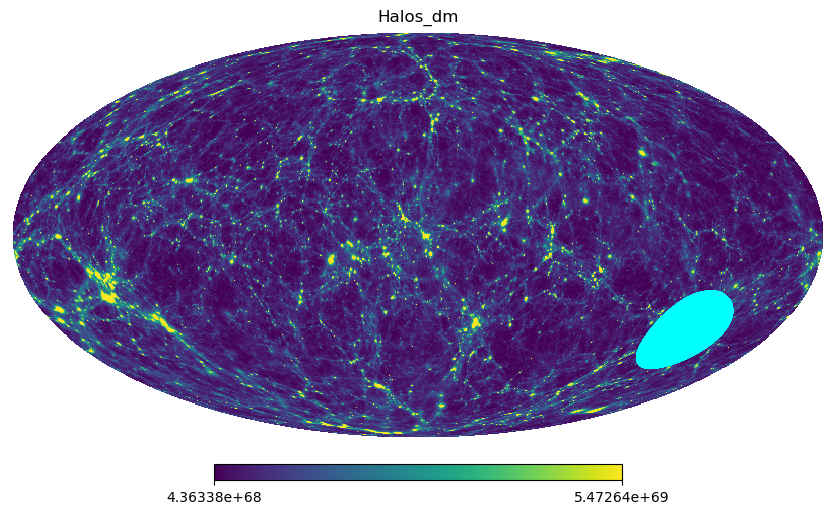

In [60]:
hp.mollview(mapa_dm,title="Halos_dm",cmap="viridis",min=np.nanpercentile(mapa_dm, 1),max=np.nanpercentile(mapa_dm, 99))

hp.projscatter(t,p,lonlat=False,s=3,color="cyan")
plt.savefig('gg.png')
plt.show()

In [65]:
print('theta:')
print(np.degrees(t).min(), np.degrees(t).max())

print("phi:")
print(np.degrees(p).min(), np.degrees(p).max())

theta:
110.81859171851505 139.71851131696167
phi:
207.20067446114177 242.80209790201891


In [68]:
phi_min=np.degrees(p).min()
phi_max=np.degrees(p).max()
theta_min=np.degrees(t).min()
theta_max=np.degrees(t).max()

In [69]:
lat_min = 90 - theta_max
lat_max = 90 - theta_min

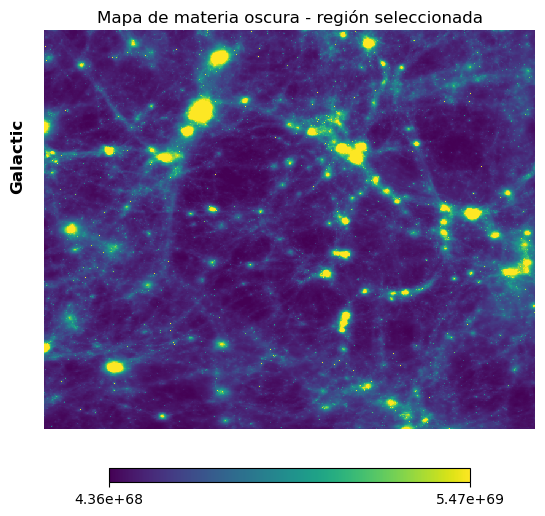

In [74]:
hp.cartview(
    mapa_dm,
    lonra=[phi_min, phi_max],
    latra=[lat_min, lat_max],
    coord='G',
    title='Mapa de materia oscura - región seleccionada',
    cmap='viridis',
    min=np.nanpercentile(mapa_dm, 1),
    max=np.nanpercentile(mapa_dm, 99),
    flip='astro'
)
hp.projscatter(
    t,
    p,
    lonlat=True,
    s=10,
    color='cyan'
)
plt.show()

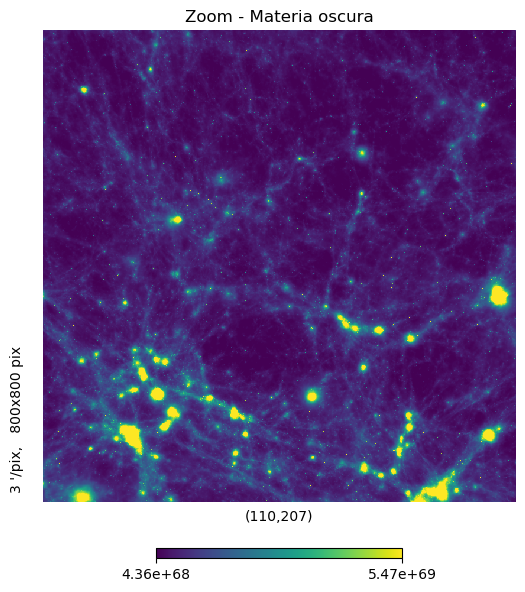

In [64]:
hp.gnomview(posicion_dm,rot=[110, 207],xsize=800,reso=3,title="Zoom - Materia oscura",cmap="viridis",min=np.nanpercentile(posicion_dm, 1),max=np.nanpercentile(posicion_dm, 99),cbar=True)


hp.projscatter(t, p,lonlat=True,s=10,color="cyan")

plt.savefig("zoom_dm.png", dpi=300, bbox_inches="tight")
plt.show()

In [38]:
for key in h5file2.keys():
    print("\n", key)
    print(h5file2[key].attrs)


 BlackHoleMass
{'Conversion factor to CGS (not including cosmological corrections)': array([1.98841e+43]), 'Expression for physical CGS units': np.bytes_(b'U_M  [ g ]'), 'U_I exponent': array([0.], dtype=float32), 'U_L exponent': array([0.], dtype=float32), 'U_M exponent': array([1.], dtype=float32), 'U_T exponent': array([0.], dtype=float32), 'U_t exponent': array([0.], dtype=float32), 'a-scale exponent': array([0.], dtype=float32), 'comoving_inner_radius': array([3.00000141]), 'comoving_outer_radius': array([217.56069793]), 'expected_sum': array([105083.74499074]), 'h-scale exponent': array([0.], dtype=float32), 'nside': array([4096]), 'number_of_pixels': array([201326592]), 'pixel_ordering_scheme': np.bytes_(b'ring')}

 ComptonY
{'Conversion factor to CGS (not including cosmological corrections)': array([1.]), 'Expression for physical CGS units': np.bytes_(b'[ - ] '), 'U_I exponent': array([0.], dtype=float32), 'U_L exponent': array([0.], dtype=float32), 'U_M exponent': array([0.],

In [39]:
print("mínimo:", np.nanmin(posicion_dm))
print("máximo:", np.nanmax(posicion_dm))
print("percentil 1:", np.nanpercentile(posicion_dm, 1))
print("percentil 50:", np.nanpercentile(posicion_dm, 50))
print("percentil 99:", np.nanpercentile(posicion_dm, 99))

mínimo: 2.4492857060662816e+68
máximo: 1.4484849287994066e+71
percentil 1: 4.363377601848976e+68
percentil 50: 9.330745612608567e+68
percentil 99: 5.4726428048821805e+69


In [40]:
print("Conversion factor:", 
      h5file2["DM"].attrs["Conversion factor to CGS (not including cosmological corrections)"])

Conversion factor: [1.05026504e-49]


In [45]:
print(h5file2['DM'].attrs)


{'Central redshift assumed for correction': np.float64(0.02534078905), 'Conversion factor to CGS (not including cosmological corrections)': array([1.05026504e-49]), 'Correction applied': 'Multiplied by 1/(1+(z_min+z_max)/2) to compensate for bug in original output', 'Correction factor': np.float64(0.9752854959827759), 'Expression for physical CGS units': np.bytes_(b'U_L^-2  [ cm^-2 ]'), 'U_I exponent': array([0.], dtype=float32), 'U_L exponent': array([-2.], dtype=float32), 'U_M exponent': array([0.], dtype=float32), 'U_T exponent': array([0.], dtype=float32), 'U_t exponent': array([0.], dtype=float32), 'a-scale exponent': array([0.], dtype=float32), 'comoving_inner_radius': array([3.00000141]), 'comoving_outer_radius': array([217.56069793]), 'expected_sum': array([1.34661428e+11]), 'h-scale exponent': array([0.], dtype=float32), 'nside': array([4096]), 'number_of_pixels': array([201326592]), 'pixel_ordering_scheme': np.bytes_(b'ring')}


In [49]:
print(h5file2['Units'].attrs)

{'Unit current in cgs (U_I)': array([1.]), 'Unit length in cgs (U_L)': array([3.08567758e+24]), 'Unit mass in cgs (U_M)': array([1.98841e+43]), 'Unit temperature in cgs (U_T)': array([1.]), 'Unit time in cgs (U_t)': array([3.08567758e+19])}
